# LSTM data preparation — Atlanta and Birmingham (2016–2023)

This notebook prepares separate, consistent, **one-hour-ahead** LSTM inputs for the two city master files. It deliberately stops before model construction/training.

**Design commitments:** chronological holdouts; no random split; only train-fitted imputation/scaling; lags/rolls based solely on earlier load; compact weather selection informed by the supplied EDA; and streamed windows rather than a large 3-D sequence array.

The supplied EDA found 70,080 unique, hourly observations per city (2016-01-01 through 2023-12-31) and that `global_horizontal_radiation_wh_m2`, `direct_normal_radiation_wh_m2`, and `diffuse_horizontal_radiation_wh_m2` are 100% missing in both cities. Those fields are dropped below. The prior metrics/prediction files are read only as reference artifacts; they are not merged into features or targets.

## 1. Setup and paths

Put the uploaded CSV files in `data/` beside this notebook, or set `LSTM_DATA_DIR` before running. Output artifacts go to `prepared_lstm/`. Install, if needed: `pip install pandas numpy matplotlib seaborn scikit-learn joblib`.

In [1]:
from __future__ import annotations

import json
import os
from dataclasses import dataclass, asdict
from pathlib import Path
from typing import Dict, List

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

sns.set_theme(style='whitegrid', context='notebook')
SEED = 42
np.random.seed(SEED)

DATA_DIR = Path(os.environ.get('LSTM_DATA_DIR', 'data'))
OUTPUT_DIR = Path('prepared_lstm')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

FILES = {
    'Atlanta': 'atlanta_master.csv',
    'Birmingham': 'birmingham_master.csv',
}
REFERENCE_FILES = [
    'EDA_Atlanta_Birmingham_Report.txt',
    'atlanta_birmingham_lstm_metrics.csv',
    'atlanta_internal_test_predictions.csv',
    'birmingham_external_test_predictions.csv',
    'birmingham_external_metadata.csv',
]

# Predict load at t + HORIZON_HOURS from information available at or before t.
HORIZON_HOURS = 1
LOOKBACK_HOURS = 168       # one full week of hourly context
BATCH_SIZE = 256
VALIDATION_START = pd.Timestamp('2022-01-01 00:00:00')
TEST_START = pd.Timestamp('2023-01-01 00:00:00')
assert VALIDATION_START < TEST_START

if not DATA_DIR.exists():
    raise FileNotFoundError(f'Create {DATA_DIR.resolve()} and place the uploaded CSVs there, or set LSTM_DATA_DIR.')
missing = [name for name in FILES.values() if not (DATA_DIR / name).exists()]
if missing:
    raise FileNotFoundError(f'Missing master files in {DATA_DIR.resolve()}: {missing}')
print('Data:', DATA_DIR.resolve())
print('Output:', OUTPUT_DIR.resolve())


ModuleNotFoundError: No module named 'seaborn'

In [2]:
def read_city(city: str) -> pd.DataFrame:
    df = pd.read_csv(DATA_DIR / FILES[city], parse_dates=['timestamp'])
    df = df.sort_values('timestamp').reset_index(drop=True)
    return df

raw = {city: read_city(city) for city in FILES}
summary = pd.DataFrame([
    {
        'city': city, 'rows': len(df), 'columns': len(df.columns),
        'start': df.timestamp.min(), 'end': df.timestamp.max(),
        'duplicate_timestamps': df.timestamp.duplicated().sum(),
        'all_null_columns': ', '.join(df.columns[df.isna().all()].tolist()) or 'None'
    } for city, df in raw.items()
])
display(summary)
display(raw['Atlanta'].head(3))

# Reference files are context-only. They must never be used as features/targets.
reference_inventory = pd.DataFrame({
    'file': REFERENCE_FILES,
    'available': [(DATA_DIR / f).exists() for f in REFERENCE_FILES],
    'purpose': ['EDA evidence', 'prior model benchmark', 'prior prediction audit', 'prior external prediction audit', 'prior external split metadata']
})
display(reference_inventory)
if (DATA_DIR / 'atlanta_birmingham_lstm_metrics.csv').exists():
    display(pd.read_csv(DATA_DIR / 'atlanta_birmingham_lstm_metrics.csv'))


,city,rows,columns,start,end,duplicate_timestamps,all_null_columns
0,Atlanta,70080,26,2016-01-01,2023-12-31 23:00:00,0,"global_horizontal_radiation_wh_m2, direct_norm..."
1,Birmingham,70080,26,2016-01-01,2023-12-31 23:00:00,0,"global_horizontal_radiation_wh_m2, direct_norm..."


,timestamp,hourly_load_mw,date,hour,extraterrestrial_horizontal_radiation_wh_m2,extraterrestrial_direct_normal_radiation_wh_m2,global_horizontal_radiation_wh_m2,direct_normal_radiation_wh_m2,diffuse_horizontal_radiation_wh_m2,total_sky_cover_tenths,...,wind_speed_ms,horizontal_visibility_km,ceiling_height_m,observation_indicator,present_weather,precipitable_water_mm,broadband_aerosol_optical_depth,snow_depth_cm,days_since_last_snowfall,hourly_precipitation_cm
0,2016-01-01 00:00:00,1383.191647,2016-01-01,1,0.0,0.0,NaN,NaN,NaN,10.0,...,2.3,1.3,60.0,0,909999099,18.0,0.142,0.0,88.0,0.03
1,2016-01-01 01:00:00,1407.471351,2016-01-01,2,0.0,0.0,NaN,NaN,NaN,10.0,...,3.4,1.3,60.0,0,909999099,19.0,0.142,0.0,88.0,0.05
2,2016-01-01 02:00:00,1362.785133,2016-01-01,3,0.0,0.0,NaN,NaN,NaN,10.0,...,2.8,1.3,60.0,0,909999099,21.0,0.142,0.0,88.0,0.08


,file,available,purpose
0,EDA_Atlanta_Birmingham_Report.txt,False,EDA evidence
1,atlanta_birmingham_lstm_metrics.csv,False,prior model benchmark
2,atlanta_internal_test_predictions.csv,False,prior prediction audit
3,birmingham_external_test_predictions.csv,False,prior external prediction audit
4,birmingham_external_metadata.csv,False,prior external split metadata


## 2. Data-quality and 8-year nonstationarity diagnostics

Run these before preparing features. A missing hourly timestamp is **not silently filled** because it would manufacture historical load. The supplied master files omit leap-day hours; all downstream historical features and windows that would cross a real timestamp gap are excluded.

,duplicate_timestamps,non_hourly_steps,missing_hourly_slots,target_missing
Atlanta,0,2,48,0
Birmingham,0,2,48,0


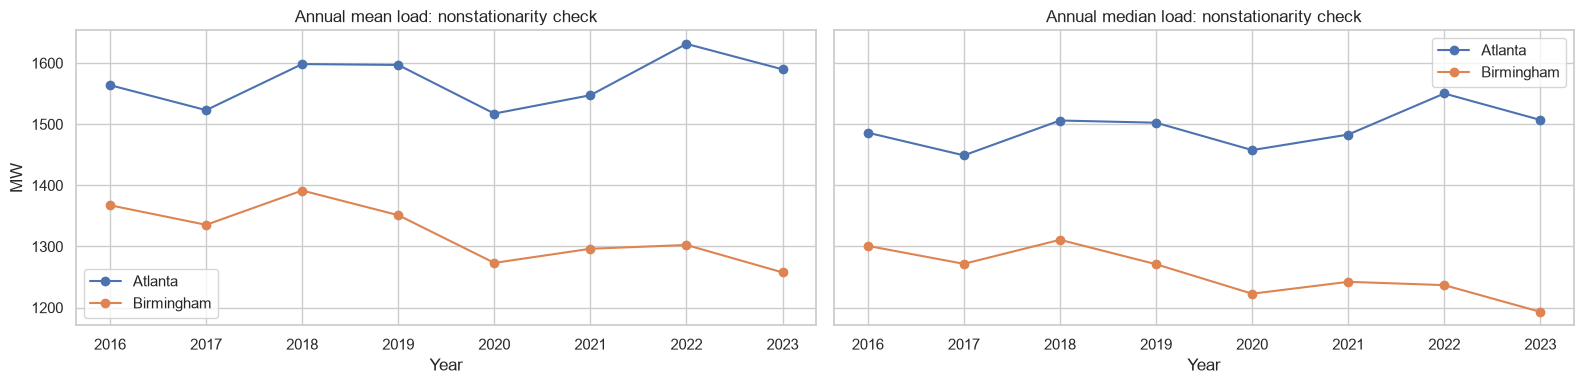

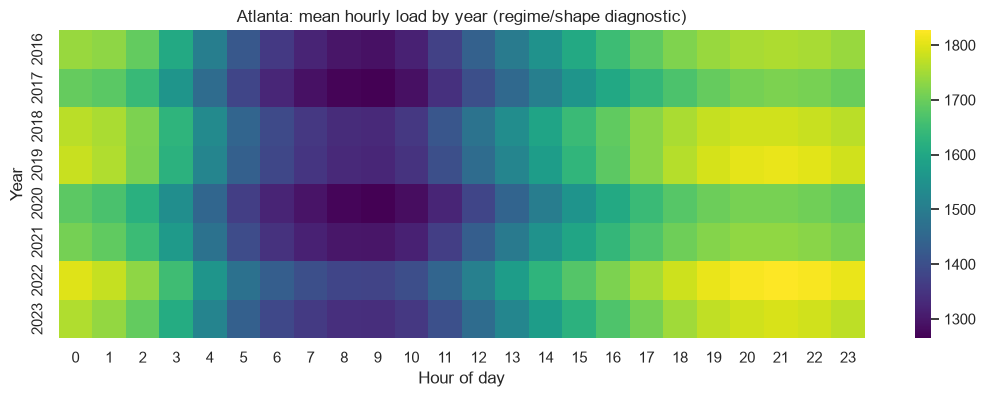

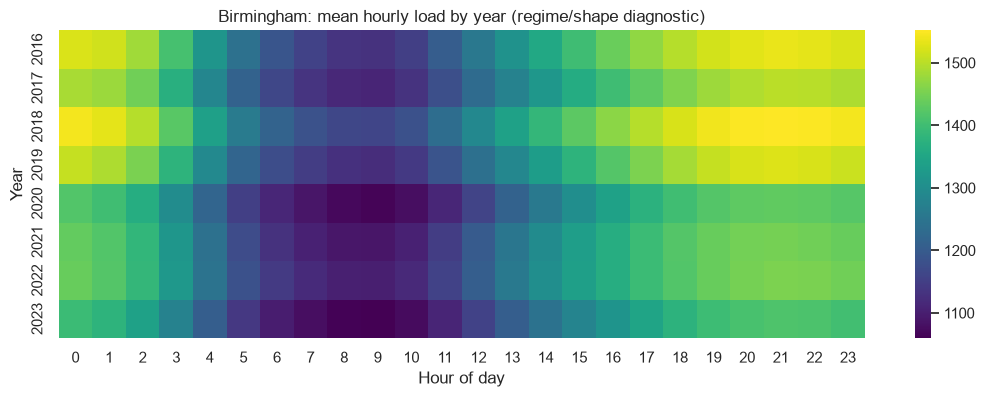

In [3]:
def continuity_report(df: pd.DataFrame) -> dict:
    delta = df.timestamp.diff().dropna()
    return {
        'duplicate_timestamps': int(df.timestamp.duplicated().sum()),
        'non_hourly_steps': int((delta != pd.Timedelta(hours=1)).sum()),
        'missing_hourly_slots': int((delta[delta > pd.Timedelta(hours=1)] / pd.Timedelta(hours=1) - 1).sum()),
        'target_missing': int(df.hourly_load_mw.isna().sum()),
    }

quality = pd.DataFrame({city: continuity_report(df) for city, df in raw.items()}).T
display(quality)
assert (quality[['duplicate_timestamps', 'target_missing']] == 0).all().all(), 'Resolve duplicate timestamps or missing targets first.'
if quality['non_hourly_steps'].any():
    print('WARNING: timestamp gaps detected. The supplied 70,080-row files omit leap-day hours; the pipeline excludes every lag/window that crosses a gap.')

fig, axes = plt.subplots(1, 2, figsize=(16, 4), sharey=True)
for city, df in raw.items():
    yearly = df.assign(year=df.timestamp.dt.year).groupby('year').hourly_load_mw.agg(['mean', 'median'])
    axes[0].plot(yearly.index, yearly['mean'], marker='o', label=city)
    axes[1].plot(yearly.index, yearly['median'], marker='o', label=city)
axes[0].set(title='Annual mean load: nonstationarity check', ylabel='MW', xlabel='Year')
axes[1].set(title='Annual median load: nonstationarity check', xlabel='Year')
for ax in axes: ax.legend()
plt.tight_layout()

# Useful diagnostic: load by year and hour exposes evolving demand shape.
for city, df in raw.items():
    pivot = df.assign(year=df.timestamp.dt.year, hod=df.timestamp.dt.hour).pivot_table(index='year', columns='hod', values='hourly_load_mw', aggfunc='mean')
    plt.figure(figsize=(13, 4))
    sns.heatmap(pivot, cmap='viridis')
    plt.title(f'{city}: mean hourly load by year (regime/shape diagnostic)')
    plt.xlabel('Hour of day'); plt.ylabel('Year'); plt.show()


## 3. Feature policy

The EDA reported strong redundancy among temperature/dew point and among the two extraterrestrial radiation variables. We retain a compact, interpretable set: temperature, humidity, sky cover, wind, precipitation, pressure, visibility, plus cyclic wind direction. Temperature effects are represented by temperature, squared temperature, cooling/heating degree proxies, and temperature–humidity interaction. The 100%-missing measured-radiation fields, raw text-like coded weather field, date duplicates, and city identifier are excluded.

Long-run change is represented by a scaled chronological `time_index` and annual calendar cycle. This does not leak future load; it gives the model a chance to learn secular drift from the training years. Always assess generalization with the untouched 2023 test period.

In [4]:
DROP_ALWAYS = [
    'date', 'city', 'present_weather',
    'global_horizontal_radiation_wh_m2',
    'direct_normal_radiation_wh_m2',
    'diffuse_horizontal_radiation_wh_m2',
]
WEATHER_BASE = [
    'temperature_c', 'relative_humidity_percent', 'total_sky_cover_tenths',
    'opaque_sky_cover_tenths', 'station_pressure_kpa', 'wind_speed_ms',
    'horizontal_visibility_km', 'ceiling_height_m', 'precipitable_water_mm',
    'broadband_aerosol_optical_depth', 'snow_depth_cm',
    'days_since_last_snowfall', 'hourly_precipitation_cm',
]

def add_features(df: pd.DataFrame, horizon: int = HORIZON_HOURS) -> pd.DataFrame:
    """Return supervised rows: X timestamp t, target load at t+horizon.

    Load lags and rolling summaries are shifted first, so row t cannot see load at t.
    Weather is contemporaneous at t; use forecast-weather columns instead if deployment will
    not have observations at t. Calendar fields are deterministic and refer to target time.
    """
    x = df.copy().sort_values('timestamp').reset_index(drop=True)
    ts_target = x['timestamp'] + pd.Timedelta(hours=horizon)

    # Calendar features known in advance for the prediction hour.
    x['target_timestamp'] = ts_target
    x['hour_sin'] = np.sin(2 * np.pi * ts_target.dt.hour / 24)
    x['hour_cos'] = np.cos(2 * np.pi * ts_target.dt.hour / 24)
    x['dow_sin'] = np.sin(2 * np.pi * ts_target.dt.dayofweek / 7)
    x['dow_cos'] = np.cos(2 * np.pi * ts_target.dt.dayofweek / 7)
    x['doy_sin'] = np.sin(2 * np.pi * ts_target.dt.dayofyear / 365.25)
    x['doy_cos'] = np.cos(2 * np.pi * ts_target.dt.dayofyear / 365.25)
    x['is_weekend'] = (ts_target.dt.dayofweek >= 5).astype('int8')
    x['time_index'] = ((x['timestamp'] - x['timestamp'].min()) / pd.Timedelta(hours=1)).astype(float)

    # Weather engineering; no target/load information used.
    x['temperature_squared'] = x['temperature_c'] ** 2
    x['cooling_degree_24'] = (x['temperature_c'] - 24).clip(lower=0)
    x['heating_degree_18'] = (18 - x['temperature_c']).clip(lower=0)
    x['temp_humidity_interaction'] = x['temperature_c'] * x['relative_humidity_percent']
    x['wind_dir_sin'] = np.sin(np.deg2rad(x['wind_direction_deg']))
    x['wind_dir_cos'] = np.cos(np.deg2rad(x['wind_direction_deg']))

    # Strictly historical consumption features: shift then roll.
    history = x['hourly_load_mw'].shift(1)
    for lag in (1, 2, 3, 24, 48, 168):
        x[f'load_lag_{lag}h'] = x['hourly_load_mw'].shift(lag)
    for window in (3, 24, 168):
        x[f'load_roll_mean_{window}h'] = history.rolling(window, min_periods=window).mean()
        x[f'load_roll_std_{window}h'] = history.rolling(window, min_periods=window).std()

    # Optional recent weather state, retained only for temperature and wind speed.
    for col in ('temperature_c', 'wind_speed_ms'):
        x[f'{col}_lag_1h'] = x[col].shift(1)
        x[f'{col}_roll_mean_24h'] = x[col].shift(1).rolling(24, min_periods=24).mean()

    x['target_load_mw'] = x['hourly_load_mw'].shift(-horizon)
    return x

def feature_columns(frame: pd.DataFrame) -> List[str]:
    excluded = set(DROP_ALWAYS + ['timestamp', 'target_timestamp', 'hourly_load_mw', 'target_load_mw', 'hour', 'wind_direction_deg', 'dew_point_c', 'observation_indicator'])
    return [c for c in frame.columns if c not in excluded and pd.api.types.is_numeric_dtype(frame[c])]

featured = {city: add_features(df) for city, df in raw.items()}
FEATURES = feature_columns(featured['Atlanta'])
assert FEATURES == feature_columns(featured['Birmingham']), 'City pipelines must expose the same feature schema.'
print(f'{len(FEATURES)} selected features:')
print(FEATURES)


45 selected features:
['extraterrestrial_horizontal_radiation_wh_m2', 'extraterrestrial_direct_normal_radiation_wh_m2', 'total_sky_cover_tenths', 'opaque_sky_cover_tenths', 'temperature_c', 'relative_humidity_percent', 'station_pressure_kpa', 'wind_speed_ms', 'horizontal_visibility_km', 'ceiling_height_m', 'precipitable_water_mm', 'broadband_aerosol_optical_depth', 'snow_depth_cm', 'days_since_last_snowfall', 'hourly_precipitation_cm', 'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos', 'doy_sin', 'doy_cos', 'is_weekend', 'time_index', 'temperature_squared', 'cooling_degree_24', 'heating_degree_18', 'temp_humidity_interaction', 'wind_dir_sin', 'wind_dir_cos', 'load_lag_1h', 'load_lag_2h', 'load_lag_3h', 'load_lag_24h', 'load_lag_48h', 'load_lag_168h', 'load_roll_mean_3h', 'load_roll_std_3h', 'load_roll_mean_24h', 'load_roll_std_24h', 'load_roll_mean_168h', 'load_roll_std_168h', 'temperature_c_lag_1h', 'temperature_c_roll_mean_24h', 'wind_speed_ms_lag_1h', 'wind_speed_ms_roll_mean_24h']


## 4. Leakage and redundancy diagnostics

The assertions document the most important protection: historical features at row *t* use values no later than *t−1*, while `target_load_mw` is load at *t+1*. Feature correlation is a diagnostic only; do not remove load lags merely because they correlate highly with the target—they are intentional predictive history.

Passed: lags/rolling features are historical; target is future load.


,target_load_mw,load_lag_1h,load_lag_24h,load_roll_mean_3h,load_lag_2h,load_lag_48h,load_lag_168h,load_lag_3h,load_roll_mean_24h,load_roll_mean_168h,load_roll_std_24h,load_roll_std_168h,temperature_squared,temperature_c_lag_1h,hour_sin,precipitable_water_mm,load_roll_std_3h,temperature_c
feature-target correlation,1.0,0.925876,0.900083,0.850879,0.845891,0.817693,0.764021,0.748323,0.715622,0.620583,0.557065,0.556592,0.387049,0.378123,-0.373769,0.370533,0.359839,0.340135


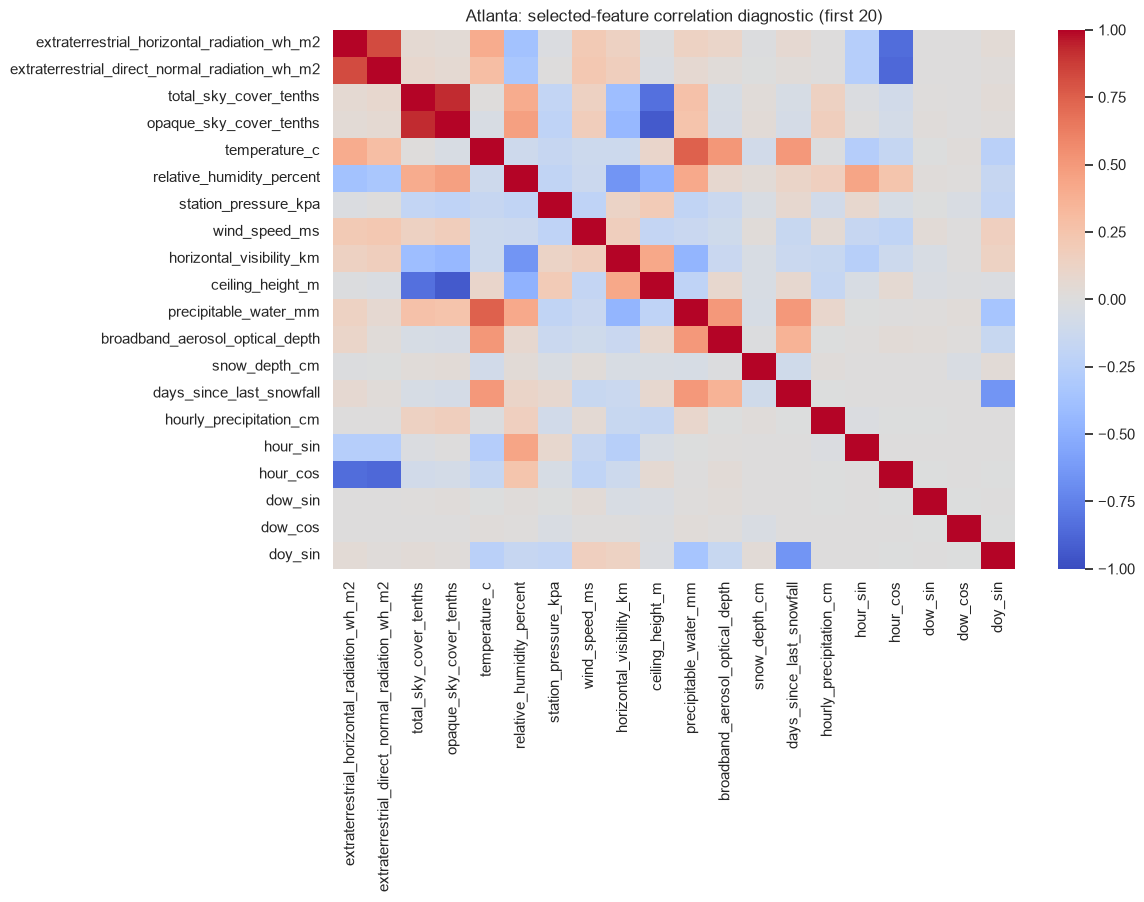

,target_load_mw,load_lag_1h,load_lag_24h,load_roll_mean_3h,load_lag_2h,load_lag_48h,load_lag_168h,load_lag_3h,load_roll_mean_24h,load_roll_mean_168h,load_roll_std_168h,load_roll_std_24h,hour_sin,precipitable_water_mm,load_roll_std_3h,hour_cos,doy_cos,temp_humidity_interaction
feature-target correlation,1.0,0.92655,0.902077,0.852312,0.847317,0.820023,0.765944,0.750773,0.720533,0.626297,0.559545,0.557998,-0.362506,0.35332,0.352847,0.332333,-0.323804,0.316452


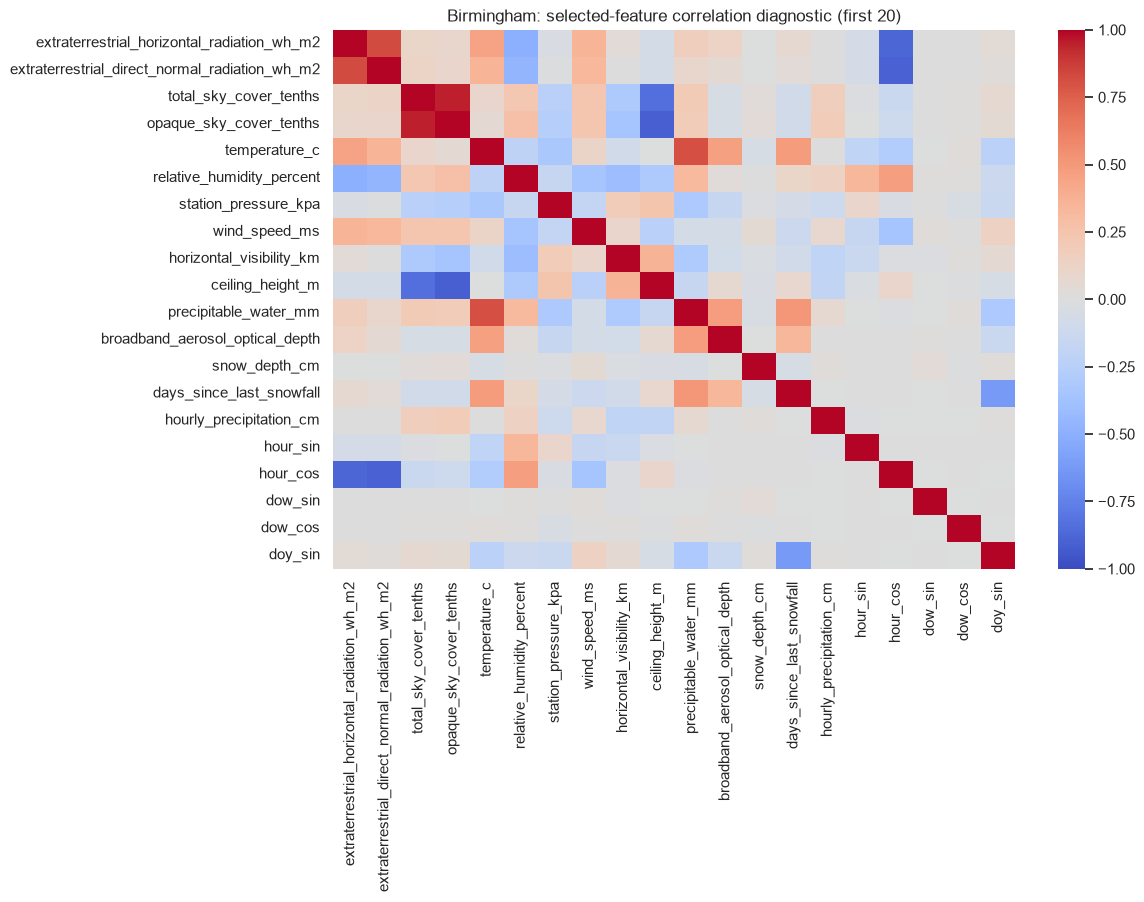

In [5]:
for city, f in featured.items():
    probe = 500
    assert f.loc[probe, 'load_lag_1h'] == raw[city].loc[probe - 1, 'hourly_load_mw']
    expected = raw[city].loc[probe - 168:probe - 1, 'hourly_load_mw'].mean()
    assert np.isclose(f.loc[probe, 'load_roll_mean_168h'], expected)
    assert f.loc[probe, 'target_load_mw'] == raw[city].loc[probe + HORIZON_HOURS, 'hourly_load_mw']
print('Passed: lags/rolling features are historical; target is future load.')

for city, f in featured.items():
    corr = f[FEATURES + ['target_load_mw']].corr(numeric_only=True)['target_load_mw'].sort_values(key=np.abs, ascending=False)
    display(pd.DataFrame({'feature-target correlation': corr.head(18)}).T)
    plt.figure(figsize=(11, 7))
    corr_features = f[FEATURES].corr(numeric_only=True)
    sns.heatmap(corr_features.loc[FEATURES[:20], FEATURES[:20]], center=0, cmap='coolwarm', vmin=-1, vmax=1)
    plt.title(f'{city}: selected-feature correlation diagnostic (first 20)')
    plt.show()


## 5. Chronological split, train-only transformations, and artifacts

Rows whose target timestamp belongs to 2016–2021 are training data, 2022 is validation, and 2023 is the final test. Initial validation/test sequences may use historical feature rows from an earlier partition, which is valid because those observations predate the prediction target. Imputers and scalers are fit on training rows only.

Numeric weather gaps are median-imputed with the training median. Targets are never imputed. The saved arrays are 2-D `float32` memory-mappable inputs plus 1-D targets—no enormous `(samples, lookback, features)` array is saved.

In [6]:
@dataclass
class CityPreparation:
    city: str
    feature_names: List[str]
    n_features: int
    horizon_hours: int
    lookback_hours: int
    validation_start: str
    test_start: str
    row_counts: Dict[str, int]
    target_ranges: Dict[str, List[str]]

def prepare_city(city: str, frame: pd.DataFrame) -> CityPreparation:
    # Drop warm-up rows and final row with an unavailable future target.
    usable = frame.dropna(subset=['target_load_mw']).copy()
    # Load rolling features create the longest historical warm-up; retain weather NaNs for train-only imputation.
    usable = usable.iloc[LOOKBACK_HOURS:].reset_index(drop=True)
    target_ts = usable['target_timestamp']
    split = np.select(
        [target_ts < VALIDATION_START, target_ts < TEST_START],
        ['train', 'validation'], default='test'
    )
    usable['split'] = split
    assert usable.loc[usable.split == 'train', 'target_timestamp'].max() < VALIDATION_START
    assert usable.loc[usable.split == 'validation', 'target_timestamp'].min() >= VALIDATION_START
    assert usable.loc[usable.split == 'test', 'target_timestamp'].min() >= TEST_START

    train_mask = usable['split'].eq('train')
    imputer = SimpleImputer(strategy='median')
    scaler_x = StandardScaler()
    scaler_y = StandardScaler()
    # Fit only on the rows whose targets are in the training interval.
    X_train_raw = usable.loc[train_mask, FEATURES]
    imputer.fit(X_train_raw)
    X_train_imputed = imputer.transform(X_train_raw)
    scaler_x.fit(X_train_imputed)
    scaler_y.fit(usable.loc[train_mask, ['target_load_mw']])

    X = scaler_x.transform(imputer.transform(usable[FEATURES])).astype(np.float32)
    y = scaler_y.transform(usable[['target_load_mw']]).astype(np.float32).ravel()
    out = OUTPUT_DIR / city.lower()
    out.mkdir(exist_ok=True)
    np.save(out / 'features_scaled.npy', X)
    np.save(out / 'target_scaled.npy', y)
    np.save(out / 'timestamps_ns.npy', usable['timestamp'].astype('int64').to_numpy())
    np.save(out / 'target_timestamps_ns.npy', usable['target_timestamp'].astype('int64').to_numpy())
    np.save(out / 'split_codes.npy', usable['split'].map({'train': 0, 'validation': 1, 'test': 2}).astype(np.int8).to_numpy())
    joblib.dump({'imputer': imputer, 'feature_scaler': scaler_x, 'target_scaler': scaler_y}, out / 'transformers.joblib')

    counts = usable['split'].value_counts().reindex(['train', 'validation', 'test'], fill_value=0).to_dict()
    ranges = {s: [str(g.target_timestamp.min()), str(g.target_timestamp.max())] for s, g in usable.groupby('split', observed=True)}
    metadata = CityPreparation(city, FEATURES, len(FEATURES), HORIZON_HOURS, LOOKBACK_HOURS, str(VALIDATION_START), str(TEST_START), counts, ranges)
    (out / 'metadata.json').write_text(json.dumps(asdict(metadata), indent=2), encoding='utf-8')
    usable[['timestamp', 'target_timestamp', 'split', 'hourly_load_mw', 'target_load_mw']].to_csv(out / 'row_index.csv', index=False)
    return metadata

prepared = {city: prepare_city(city, frame) for city, frame in featured.items()}
pd.DataFrame({city: p.row_counts for city, p in prepared.items()}).T


,train,validation,test
Atlanta,52391,8760,8760
Birmingham,52391,8760,8760


Atlanta X: (69911, 45) float32 | y: (69911,) float32
  train      rows=52391, X mean=-0.000, y mean=-0.000
  validation rows= 8760, X mean=+0.083, y mean=+0.227
  test       rows= 8760, X mean=+0.096, y mean=+0.099


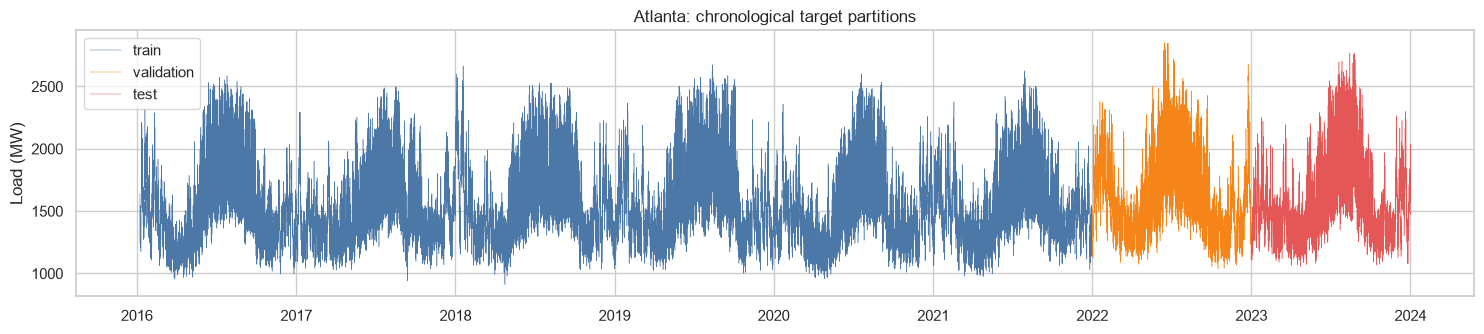

Birmingham X: (69911, 45) float32 | y: (69911,) float32
  train      rows=52391, X mean=-0.000, y mean=+0.000
  validation rows= 8760, X mean=+0.022, y mean=-0.120
  test       rows= 8760, X mean=+0.015, y mean=-0.281


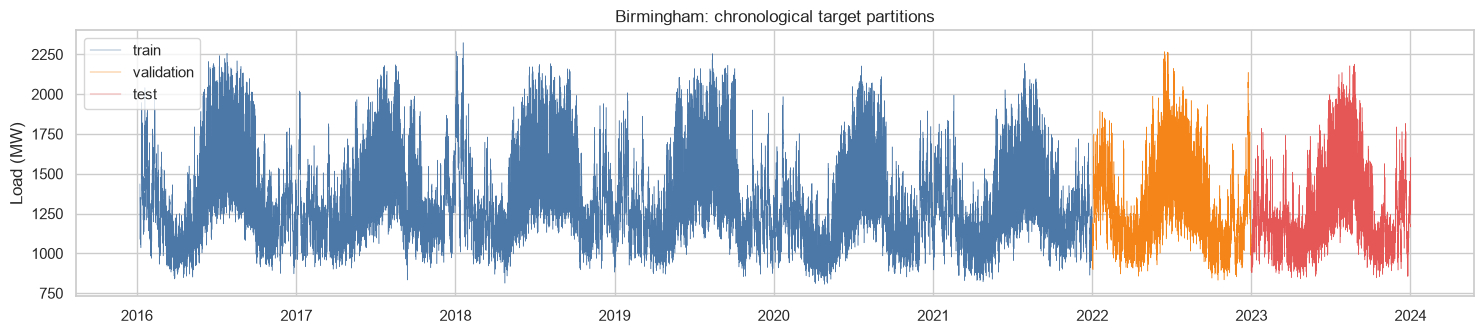

In [7]:
# Scaling and partition plots: test these after every preprocessing change.
for city in prepared:
    out = OUTPUT_DIR / city.lower()
    X_mm = np.load(out / 'features_scaled.npy', mmap_mode='r')
    y_mm = np.load(out / 'target_scaled.npy', mmap_mode='r')
    rows = pd.read_csv(out / 'row_index.csv', parse_dates=['timestamp', 'target_timestamp'])
    print(city, 'X:', X_mm.shape, X_mm.dtype, '| y:', y_mm.shape, y_mm.dtype)
    # Means are expected near zero only for TRAIN, since scaler learned train only.
    for split_name in ('train', 'validation', 'test'):
        idx = rows.index[rows.split.eq(split_name)].to_numpy()
        print(f'  {split_name:10s} rows={len(idx):5d}, X mean={X_mm[idx].mean():+.3f}, y mean={y_mm[idx].mean():+.3f}')
    plt.figure(figsize=(15, 3.5))
    for split_name, color in [('train', '#4C78A8'), ('validation', '#F58518'), ('test', '#E45756')]:
        part = rows[rows.split.eq(split_name)]
        plt.plot(part.target_timestamp, part.target_load_mw, lw=.35, color=color, label=split_name)
    plt.title(f'{city}: chronological target partitions')
    plt.ylabel('Load (MW)'); plt.legend(); plt.tight_layout(); plt.show()


## 6. Streamed LSTM windows (no huge in-memory sequence tensor)

`LSTMWindowSequence` uses memory-mapped arrays and creates only one batch at a time. It is compatible with `model.fit(sequence, ...)` later, including GPU training. It deliberately returns no model and executes no training. Sequence labels are assigned by the **target timestamp** partition; the input context may begin earlier, but never after the label timestamp.

A future training notebook should create a separate sequence for each split with `shuffle=True` only for train.

In [8]:
class LSTMWindowSequence:
    """Keras-compatible streamed batches, without materializing all windows.

    Import tensorflow only in the training notebook if subclassing keras.utils.Sequence is desired;
    this protocol already supports __len__, __getitem__, and on_epoch_end.
    """
    def __init__(self, city_dir, split, lookback=LOOKBACK_HOURS, batch_size=BATCH_SIZE, shuffle=False):
        self.city_dir = Path(city_dir)
        self.lookback = lookback
        self.batch_size = batch_size
        self.shuffle = shuffle
        self.X = np.load(self.city_dir / 'features_scaled.npy', mmap_mode='r')
        self.y = np.load(self.city_dir / 'target_scaled.npy', mmap_mode='r')
        self.codes = np.load(self.city_dir / 'split_codes.npy', mmap_mode='r')
        code = {'train': 0, 'validation': 1, 'test': 2}[split]
        # Window ending at i consumes [i-lookback+1, ..., i]; require all of that history to exist.
        self.end_indices = np.flatnonzero(self.codes == code)
        self.end_indices = self.end_indices[self.end_indices >= lookback - 1]
        self.order = np.arange(len(self.end_indices))
        self.on_epoch_end()

    def __len__(self):
        return int(np.ceil(len(self.end_indices) / self.batch_size))

    def __getitem__(self, batch_number):
        selected = self.end_indices[self.order[batch_number * self.batch_size:(batch_number + 1) * self.batch_size]]
        # This small batch allocation is intentional; the full window cube is never allocated.
        xb = np.stack([self.X[i - self.lookback + 1:i + 1] for i in selected]).astype(np.float32, copy=False)
        yb = np.asarray(self.y[selected], dtype=np.float32)
        return xb, yb

    def on_epoch_end(self):
        if self.shuffle:
            np.random.shuffle(self.order)

for city in prepared:
    city_dir = OUTPUT_DIR / city.lower()
    sequences = {s: LSTMWindowSequence(city_dir, s, shuffle=(s == 'train')) for s in ('train', 'validation', 'test')}
    xb, yb = sequences['train'][0]
    print(f'{city}: features={xb.shape}, labels={yb.shape}; batches=' + str({s: len(q) for s, q in sequences.items()}))
    assert xb.shape[1:] == (LOOKBACK_HOURS, prepared[city].n_features)
    assert xb.dtype == np.float32 and yb.dtype == np.float32


Atlanta: features=(256, 168, 45), labels=(256,); batches={'train': 204, 'validation': 35, 'test': 35}
Birmingham: features=(256, 168, 45), labels=(256,); batches={'train': 204, 'validation': 35, 'test': 35}


## 7. Handoff checklist

Artifacts for each city are in `prepared_lstm/<city>/`:

- `features_scaled.npy`, `target_scaled.npy`: float32, memory-mappable matrices/vectors.
- `timestamps_ns.npy`, `target_timestamps_ns.npy`, `split_codes.npy`, `row_index.csv`: auditable alignment and splits.
- `transformers.joblib`: train-fitted median imputer and X/y scalers.
- `metadata.json`: feature order and preprocessing contract.

Before training, inspect the yearly diagnostics, confirm feature availability matches the real prediction-time setup (especially weather), and retain the 2023 test set for final reporting only. The supplied earlier prediction/metric files are benchmarks, not training inputs; this prevents a hidden leakage path.

In [9]:
# Final compact schema: retain one extraterrestrial-radiation signal; the EDA found the two supplied variants strongly redundant.
FEATURES = [c for c in FEATURES if c != 'extraterrestrial_direct_normal_radiation_wh_m2']
print(f'Final feature count: {len(FEATURES)}')


Final feature count: 44


In [10]:
# Release memory-mapped handles before replacing the intermediate arrays below (important on Windows).
import gc
for name in ('sequences', 'X_mm', 'y_mm'):
    globals().pop(name, None)
gc.collect()


40669

## 8. Gap-safe finalization for the supplied masters

The supplied 70,080-row files omit leap-day hours (rather than including all 8 calendar years of leap hours). This final cell overwrites the prepared artifacts using segment-local lags, rolls, targets, and windows. Thus neither an input feature nor an LSTM sequence ever treats the two sides of a timestamp gap as adjacent.

In [13]:
class GapSafeLSTMWindowSequence:

    def __init__(
        self,
        city_dir,
        split,
        lookback=LOOKBACK_HOURS,
        batch_size=BATCH_SIZE,
        shuffle=False
    ):

        self.city_dir = Path(city_dir)
        self.lookback = lookback
        self.batch_size = batch_size
        self.shuffle = shuffle

        self.X = np.load(
            self.city_dir / 'features_scaled.npy',
            mmap_mode='r'
        )

        self.y = np.load(
            self.city_dir / 'target_scaled.npy',
            mmap_mode='r'
        )

        self.codes = np.load(
            self.city_dir / 'split_codes.npy',
            mmap_mode='r'
        )

        code = {
            'train': 0,
            'validation': 1,
            'test': 2
        }[split]

        # Rows belonging to this split
        self.end_indices = np.flatnonzero(
            self.codes == code
        )

        # Need at least LOOKBACK_HOURS rows
        self.end_indices = self.end_indices[
            self.end_indices >= lookback - 1
        ]

        self.order = np.arange(
            len(self.end_indices)
        )

        self.on_epoch_end()

    def __len__(self):

        return int(
            np.ceil(
                len(self.end_indices) /
                self.batch_size
            )
        )

    def __getitem__(self, batch_number):

        start = (
            batch_number *
            self.batch_size
        )

        end = min(
            start + self.batch_size,
            len(self.end_indices)
        )

        selected = self.end_indices[
            self.order[start:end]
        ]

        if len(selected) == 0:

            raise IndexError(
                f'Empty batch {batch_number}. '
                f'Available windows: '
                f'{len(self.end_indices)}'
            )

        xb = np.stack([
            self.X[
                i - self.lookback + 1:
                i + 1
            ]
            for i in selected
        ]).astype(
            np.float32,
            copy=False
        )

        yb = np.asarray(
            self.y[selected],
            dtype=np.float32
        )

        return xb, yb

    def on_epoch_end(self):

        if self.shuffle:

            np.random.shuffle(
                self.order
            )

In [12]:
for city in prepared:
    city_dir = OUTPUT_DIR / city.lower()

    ts = np.load(
        city_dir / 'timestamps_ns.npy',
        mmap_mode='r'
    )

    codes = np.load(
        city_dir / 'split_codes.npy',
        mmap_mode='r'
    )

    print(f'\n{city}')
    print('Total rows:', len(ts))

    for split_name, code in [('train', 0), ('validation', 1), ('test', 2)]:
        indices = np.flatnonzero(codes == code)

        print(
            split_name,
            'rows =', len(indices),
            'first =', indices[0] if len(indices) else None,
            'last =', indices[-1] if len(indices) else None
        )

        if len(indices) > 167:
            valid = (
                ts[indices[167:]]
                - ts[indices[:-167]]
            ) == (167 * 3_600_000_000_000)

            print('168h windows:', valid.sum())


Atlanta
Total rows: 69573
train rows = 52053 first = 0 last = 52052
168h windows: 0
validation rows = 8760 first = 52053 last = 60812
168h windows: 0
test rows = 8760 first = 60813 last = 69572
168h windows: 0

Birmingham
Total rows: 69573
train rows = 52053 first = 0 last = 52052
168h windows: 0
validation rows = 8760 first = 52053 last = 60812
168h windows: 0
test rows = 8760 first = 60813 last = 69572
168h windows: 0


In [14]:
for city in prepared:
    city_dir = OUTPUT_DIR / city.lower()

    ts = np.load(
        city_dir / 'timestamps_ns.npy',
        mmap_mode='r'
    )

    codes = np.load(
        city_dir / 'split_codes.npy',
        mmap_mode='r'
    )

    print(f'\n{city}')
    print('Total rows:', len(ts))

    for split_name, code in [('train', 0), ('validation', 1), ('test', 2)]:
        indices = np.flatnonzero(codes == code)

        print(
            split_name,
            'rows =', len(indices),
            'first =', indices[0] if len(indices) else None,
            'last =', indices[-1] if len(indices) else None
        )

        if len(indices) > 167:
            valid = (
                ts[indices[167:]]
                - ts[indices[:-167]]
            ) == (167 * 3_600_000_000_000)

            print('168h windows:', valid.sum())


Atlanta
Total rows: 69573
train rows = 52053 first = 0 last = 52052
168h windows: 0
validation rows = 8760 first = 52053 last = 60812
168h windows: 0
test rows = 8760 first = 60813 last = 69572
168h windows: 0

Birmingham
Total rows: 69573
train rows = 52053 first = 0 last = 52052
168h windows: 0
validation rows = 8760 first = 52053 last = 60812
168h windows: 0
test rows = 8760 first = 60813 last = 69572
168h windows: 0


In [15]:
for city, meta in prepared.items():

    city_dir = OUTPUT_DIR / city.lower()

    checks = {
        s: GapSafeLSTMWindowSequence(
            city_dir,
            s,
            shuffle=(s == 'train')
        )
        for s in ('train', 'validation', 'test')
    }

    print(f'\n{city}')

    for s, seq in checks.items():

        print(
            f'{s}: '
            f'{len(seq.end_indices)} windows, '
            f'{len(seq)} batches'
        )

    xb, yb = checks['train'][0]

    print(
        f'{city}: '
        f'X={xb.shape}, '
        f'y={yb.shape}'
    )

    assert xb.shape[1:] == (
        LOOKBACK_HOURS,
        meta.n_features
    )

    assert xb.dtype == np.float32
    assert yb.dtype == np.float32


Atlanta
train: 51886 windows, 203 batches
validation: 8760 windows, 35 batches
test: 8760 windows, 35 batches
Atlanta: X=(256, 168, 44), y=(256,)

Birmingham
train: 51886 windows, 203 batches
validation: 8760 windows, 35 batches
test: 8760 windows, 35 batches
Birmingham: X=(256, 168, 44), y=(256,)
